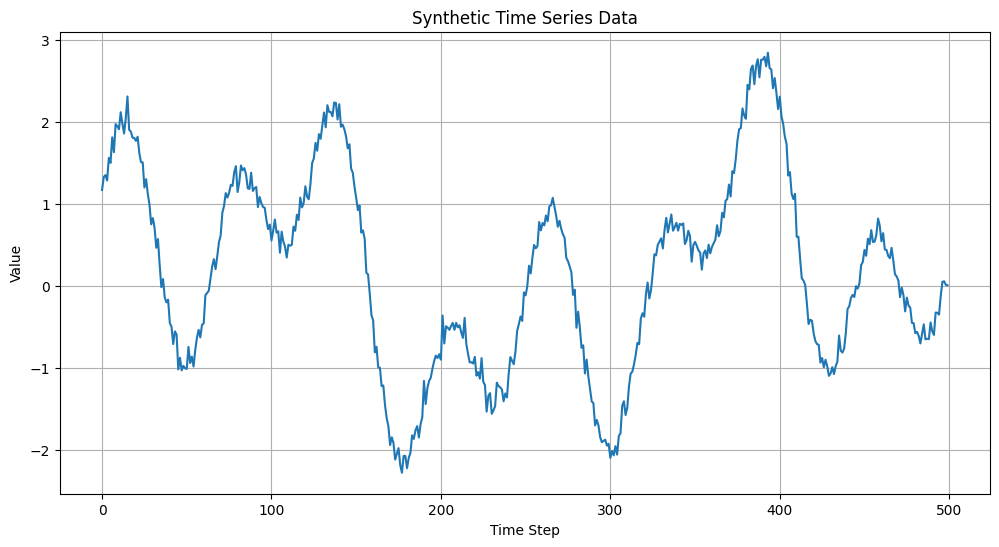

Shape of X (features): (490, 10, 1)
Shape of y (target): (490,)
Training set size: 392 samples
Testing set size: 98 samples


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.2381 - val_loss: 0.1045
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1220 - val_loss: 0.0312
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0289 - val_loss: 0.0114
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0143 - val_loss: 0.0050
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0096 - val_loss: 0.0044
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0070 - val_loss: 0.0051
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0063 - val_loss: 0.0059
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0057 - val_loss: 0.0053
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0055 - val_loss: 0.0055
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0054 - val_loss: 0.0051
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0053 - val_loss: 0.0042
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

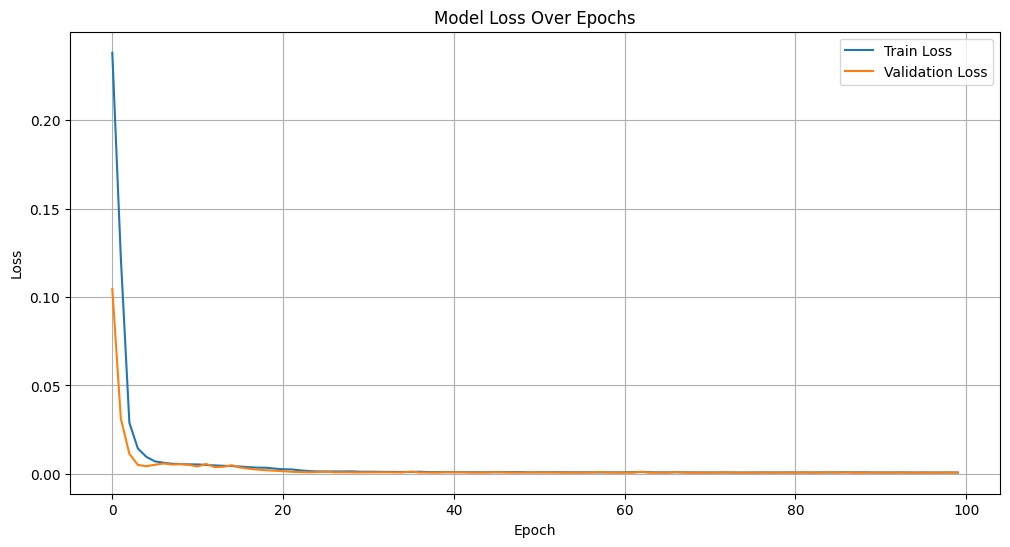

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Test RMSE: 0.134


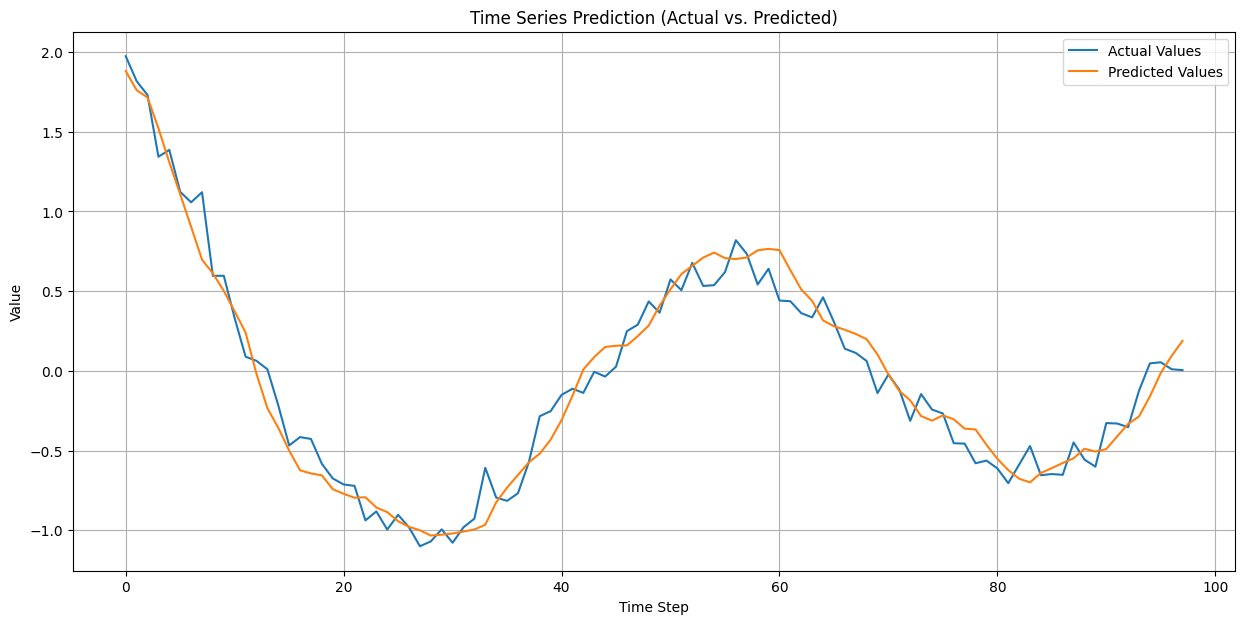

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, GRU


# Generate time-series data
def generate_time_series(num_points):
    time = np.arange(0, num_points)

    amplitude = (
        np.sin(time * 0.1)
        + np.cos(time * 0.05)
        + np.sin(time * 0.02)
    )

    noise = np.random.normal(0, 0.1, num_points)

    return amplitude + noise


num_data_points = 500
data = generate_time_series(num_data_points)


# Plot the data
plt.figure(figsize=(12, 6))
plt.plot(data)
plt.title('Synthetic Time Series Data')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.grid(True)
plt.show()


# Normalize the data
data = data.reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)


# Create sequences
def create_sequences(data, look_back):
    X, y = [], []

    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), 0])
        y.append(data[i + look_back, 0])

    return np.array(X), np.array(y)


look_back = 10

X, y = create_sequences(scaled_data, look_back)

X = np.reshape(X, (X.shape[0], X.shape[1], 1))

print(f"Shape of X (features): {X.shape}")
print(f"Shape of y (target): {y.shape}")


# Split into training and testing sets
train_size = int(len(X) * 0.8)

X_train = X[0:train_size, :]
X_test = X[train_size:len(X), :]

y_train = y[0:train_size]
y_test = y[train_size:len(y)]

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")


# Build the LSTM model
model = Sequential()

model.add(
    LSTM(
        50,
        activation='relu',
        input_shape=(look_back, 1)
    )
)

model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()


# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    verbose=1,
    validation_data=(X_test, y_test)
)


# Plot training and validation loss
plt.figure(figsize=(12, 6))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


# Make predictions
test_predict = model.predict(X_test)


# Convert predictions to original scale
test_predict = scaler.inverse_transform(test_predict)

y_test_inverse = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)


# Calculate RMSE
rmse = np.sqrt(
    mean_squared_error(y_test_inverse, test_predict)
)

print(f"Test RMSE: {rmse:.3f}")


# Plot actual vs predicted values
plt.figure(figsize=(15, 7))

plt.plot(y_test_inverse, label='Actual Values')
plt.plot(test_predict, label='Predicted Values')

plt.title('Time Series Prediction (Actual vs. Predicted)')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()